# 초구 예측 — 베이스라인
구종 → 위치 순서로, 각 단계 기준 모델 = 그 투수가 경기 전날까지 하던 대로

- 파라미터 선택: 2019 시즌 / 최종 평가: 2020 시즌 (해당 경기 전날까지 기록만 사용, 같은 날 더블헤더 1차전도 제외)
- 평가 두 가지
  - 단계별 (5, 6): 위치에 실제 구종을 넣고 평가 → 각 단계 모델 자체의 성능 (구종을 완벽히 맞혔을 때)
  - 실전 (7): ①에서 예측한 구종으로 위치를 이어서 예측 → 실제로 쓸 때의 성능. 다음 모델은 이 값과 비교
- 이후: 8 요약 (CSV·공별 예측 저장) / 9 보정 / 10 분류 지표 / 11 실전 출력 (누적 80%까지 구종 보여 주기)
- 구종 표시가 의심되는 공(`flag_speed_gap`·`flag_fast_neg_z`)은 제외

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr, log_softmax  # scipy.optimize는 이 PC에서 차단(_trlib DLL)되어 쓰지 않음 -> 재보정은 numpy로 직접 계산

VAL_YEAR, TEST_YEAR = 2019, 2020
BALL, HALF_W = 7.4, 21.6
MERGE = {}

## 1. 데이터

In [2]:
m = pd.read_parquet("pitch_model.parquet")
m = m.sort_values(["gameID", "pit_no"]).reset_index(drop=True)
m["game_date"] = pd.to_datetime(m["gameID"].str[:8], format="%Y%m%d")
m["pitch_type"] = m["pitch_stuff"].replace(MERGE)
m["same_side"] = (m["p_throws"] == m["STANCE"]).astype(int)  # 투수 손 - 타자 스탠스 비교 (같은 손 슬라이더, 반대 손 체인지업)
for c in ["TOP_SZ_CM", "BOTTOM_SZ_CM"]:
    m[c] = m[c].round(1)  # 존 높이 부동소수점 오차 제거
m["label_doubt"] = m["flag_speed_gap"] | m["flag_fast_neg_z"]  # 구종 표시 의심

names = (pd.read_parquet("pitch_clean_full.parquet", columns=["pitcher_code", "pitcher_name"])
         .drop_duplicates().set_index("pitcher_code")["pitcher_name"])
print(m.shape)
print("구종:", sorted(m["pitch_type"].unique()))

(197102, 61)
구종: ['CHUP', 'CURV', 'CUTT', 'FAST', 'FORK', 'KNUC', 'SINK', 'SLID', 'TWOS']


## 2. 위치 타깃

타자 기준 좌표 (`plate_x_in_CM`: + = 몸쪽), 높이는 그 공의 타자 존(TOP/BOTTOM) 기준. 공 하나 = 7.4cm

```
  C 높몸 │       C 높        │ C 높밖
 ───────┼────┬────┬────┬────┼────────
        │  S │  S │  S │  S │
    C   ├────┼────┼────┼────┤    C
   몸쪽  │  S │  H │  H │  S │  바깥쪽
        ├────┼────┼────┼────┤
        │  S │  H │  H │  S │
        ├────┼────┼────┼────┤
        │  S │  S │  S │  S │
 ───────┼────┴────┴────┴────┼────────
  C 낮몸 │       C 낮        │ C 낮밖
```

- 좌우 경계: ±14.2 (Heart) / ±29 (Shadow 바깥선), Heart는 x=0에서 몸쪽·바깥 나눔
- 높이 경계: BOTTOM±7.4, 존 가운데, TOP±7.4
- Heart 4 + Shadow 12 + Chase 8 = 24칸
- 분석용: Chase 중 Shadow 바깥선에서 공 2개(14.8cm) 넘게 벗어나면 Waste

In [3]:
X_EDGES = np.array([-HALF_W - BALL, -HALF_W + BALL, 0, HALF_W - BALL, HALF_W + BALL])  # 바깥 → 몸쪽

def z_edges(top, bot):
    return np.column_stack([bot - BALL, bot + BALL, (top + bot) / 2, top - BALL, top + BALL])  # 높이 경계 (타자별 존 기준 받을 수 있게)

def cell_name(zi, xi):
    side = "몸" if xi >= 3 else "밖"
    if zi in (0, 5) or xi in (0, 5):
        return "C_" + ("높" if zi == 5 else "낮" if zi == 0 else "") + (side if xi in (0, 5) else "")
    row = {4: "상띠", 3: "상", 2: "하", 1: "하띠"}[zi]
    col = {1: "밖띠", 2: "밖", 3: "몸", 4: "몸띠"}[xi]
    return ("H_" + row + col) if zi in (2, 3) and xi in (2, 3) else ("S_" + row + "-" + col)

CELL_NAMES = np.array([cell_name(zi, xi) for zi in range(6) for xi in range(6)])   # zi*6 + xi
ZONES = list(dict.fromkeys(CELL_NAMES))
CELL2ZONE = (CELL_NAMES[:, None] == np.array(ZONES)[None, :]).astype(float)
ZONE_GROUP = np.array([z[0] for z in ZONES])
GROUP2 = (ZONE_GROUP[:, None] == np.array(["H", "S", "C"])[None, :]).astype(float)
assert len(ZONES) == 24

x = m["plate_x_in_CM"].to_numpy()
z = m["CROSS_PLATE_Z_CM"].to_numpy()
top, bot = m["TOP_SZ_CM"].to_numpy(), m["BOTTOM_SZ_CM"].to_numpy()
xi = np.digitize(x, X_EDGES)
zi = (z[:, None] >= z_edges(top, bot)).sum(1)
m["cell"] = zi * 6 + xi
m["zone"] = CELL_NAMES[m["cell"]]
m["zone_group"] = m["zone"].str[0]
m["z_norm"] = (z - bot) / (top - bot)  # 타자 존 기준으로 높이 맞추기 (좌표 예측용) 0 = 아랫선, 1 = 윗선

out = np.maximum.reduce([np.abs(x) - (HALF_W + BALL), z - (top + BALL), (bot - BALL) - z])
m["attack"] = np.select([m["zone_group"].eq("H"), m["zone_group"].eq("S"), out <= 2 * BALL],
                        ["Heart", "Shadow", "Chase"], "Waste")  # Waste (분석용)

## 3. 초구

In [4]:
fp = m[m["ball_before"].eq(0) & m["strike_before"].eq(0) & ~m["label_doubt"]].reset_index(drop=True)  # 초구 0-0
CLASSES = sorted(m["pitch_type"].unique())  # 구종 목록

# 위치 기준 모델용: 좌표 1, 2차 모멘트 (가우시안 평균, 공분산 계산용)
fp["zn"] = fp["z_norm"]
fp["xx"], fp["zz"], fp["xz"] = fp["plate_x_in_CM"] ** 2, fp["zn"] ** 2, fp["plate_x_in_CM"] * fp["zn"]
fp = fp.rename(columns={"plate_x_in_CM": "x"})
MOM = ["x", "zn", "xx", "zz", "xz"]

fp = pd.concat([fp,
                pd.get_dummies(fp["pitch_type"]).reindex(columns=CLASSES, fill_value=0).astype(float),
                pd.get_dummies(fp["zone"]).reindex(columns=ZONES, fill_value=0).astype(float)], axis=1)
y_type = fp["pitch_type"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()  # 실제 구종 번호
y_zone = fp["zone"].map({c: i for i, c in enumerate(ZONES)}).to_numpy()  # 실제 존 번호
val = fp["GYEAR"].eq(VAL_YEAR).to_numpy()
test = fp["GYEAR"].eq(TEST_YEAR).to_numpy()

print(f"초구 {len(fp):,}개 (검증 {val.sum():,} / 평가 {test.sum():,})")
print(fp.groupby("GYEAR").size().to_dict())
print((fp["zone_group"].value_counts(normalize=True).round(3)).to_dict())
print(fp["attack"].value_counts(normalize=True).round(3).to_dict())

초구 50,709개 (검증 13,458 / 평가 12,615)
{2017: 12241, 2018: 12395, 2019: 13458, 2020: 12615}
{'C': 0.407, 'S': 0.364, 'H': 0.23}
{'Shadow': 0.364, 'Chase': 0.247, 'Heart': 0.23, 'Waste': 0.16}


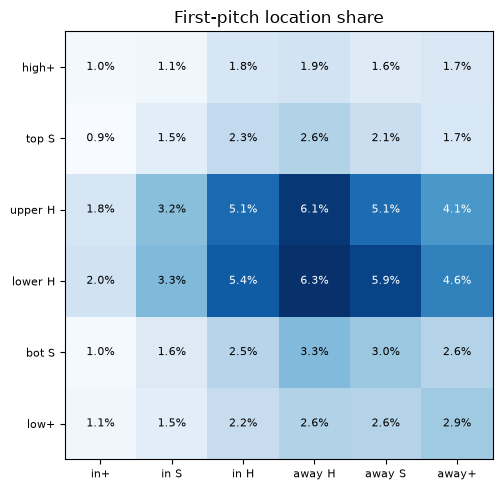

In [5]:
# 초구 위치 분포 (몸쪽이 왼쪽 = 포수 시점 우타자 기준)
share = np.bincount(fp["cell"], minlength=36).reshape(6, 6) / len(fp)
grid = share[::-1, ::-1]  # 위 = 높게, 왼쪽 = 몸쪽
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(grid, cmap="Blues")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{grid[i, j]:.1%}", ha="center", va="center", fontsize=8,
                color="white" if grid[i, j] > share.max() * 0.6 else "black")
ax.set_xticks(range(6), ["in+", "in S", "in H", "away H", "away S", "away+"], fontsize=8)
ax.set_yticks(range(6), ["high+", "top S", "upper H", "lower H", "bot S", "low+"], fontsize=8)
ax.set_title("First-pitch location share")
plt.tight_layout()
plt.show()

## 4. 공통 함수

- `prior_table`: 그룹(투수, 투수×구종 등)·경기 날짜별 누적 합계. `half_life`를 주면 최근 공일수록 가중 (공 N개마다 가중치 절반)
- `lookup`: 각 공의 경기 날짜 전날까지 누적값 (`merge_asof`, 같은 날 제외)
- `shrink`: 표본이 적으면 상위 그룹 값 쪽으로 당김 → (합계 + k × 상위값) / (개수 + k)
- `prob_metrics`: log loss, 상위 k개 안에 정답 비율

In [6]:
_TABLES = {}

def prior_table(data, keys, cols, half_life=None):
    ck = (id(data), tuple(keys), tuple(cols), half_life)
    if ck in _TABLES:
        return _TABLES[ck]
    d = data.sort_values(["game_date", "gameID", "pit_no"])
    X = d[cols].to_numpy(float)
    ok = ~np.isnan(X)
    X = np.where(ok, X, 0.0)
    dates = d["game_date"].to_numpy()
    decay = 0.5 ** (1 / half_life) if half_life else 1.0  # 반감기 가중 (그룹에서 던진 공 개수 기준)
    recs = []
    for key, idx in d.groupby(keys, sort=False).indices.items():
        key = key if isinstance(key, tuple) else (key,)
        S, N = np.zeros(len(cols)), np.zeros(len(cols))  # 누적 합계 S, 누적 개수 N 초기화
        dd = dates[idx]
        starts = np.flatnonzero(np.r_[True, dd[1:] != dd[:-1]])
        for s, e in zip(starts, np.r_[starts[1:], len(idx)]):
            blk = idx[s:e]
            w = decay ** np.arange(len(blk) - 1, -1, -1)  # 그날 공들의 가중치
            S = S * decay ** len(blk) + w @ X[blk]  # 기존 합계를 그날 던진 공 수만큼 깎고, 오늘 공들을 가중치 곱해 더하기
            N = N * decay ** len(blk) + w @ ok[blk]
            recs.append((*key, dd[s], *S, *N))
    t = pd.DataFrame(recs, columns=keys + ["game_date"] + ["S_" + c for c in cols] + ["N_" + c for c in cols])
    for k in keys + ["game_date"]:  # 자료형 맞추기, 날짜순 정렬
        t[k] = t[k].astype(data[k].dtype)
    _TABLES[ck] = t.sort_values("game_date")
    return _TABLES[ck]

def lookup(table, query, keys, cols):
    q = query[keys + ["game_date"]].copy()
    q["_row"] = np.arange(len(q))
    r = pd.merge_asof(q.sort_values("game_date"), table, on="game_date", by=keys, allow_exact_matches=False).sort_values("_row")
    return (r[["S_" + c for c in cols]].fillna(0).to_numpy(),
            r[["N_" + c for c in cols]].fillna(0).to_numpy())  # 각 행의 경기 날짜 전날까지 누적 S, N (기록 없으면 0)

def shrink(S, N, prior, k):
    return (S + k * prior) / (N + k)  # 소표본 평균 쪽으로 당기기

def prob_metrics(P, y, ks=(1, 2, 3)):
    p_true = P[np.arange(len(P)), y]  # 정답에 준 확률
    rank = (P > p_true[:, None]).sum(1)  # 정답보다 높은 확률을 받은 후보 수
    res = {"logloss": -np.log(np.clip(p_true, 1e-12, None)).mean()}  # logloss: 정답에 준 확률이 높을수록 작아짐 (틀렸는데 자신만만했으면 크게 벌점)
    res.update({f"top{k}": (rank < k).mean() for k in ks})  # top-k: 확률이 높은 순으로 k개를 골랐을 때 그 안에 정답이 있는 비율
    return res

## 5. ① 구종

| 모델 | 내용 |
| --- | --- |
| B0 | 리그 전체 초구 구종 비율 |
| B1 | 투수 초구 비율, 지난 시즌까지 (시즌 중 갱신 없음) |
| B3 | 투수 초구 비율, 경기 전날까지 갱신 (누적 / 최근 가중) |
| B4 | B3 + 같은 손·반대 손 타자로 나눈 비율 (투수 비율 쪽으로 수축) |

정확도(top1)는 대부분 직구만 맞혀서 모델 간 차이가 거의 없음 → log loss, top2 위주로 비교

In [7]:
def league_type(year):
    return fp.loc[fp["GYEAR"] < year, CLASSES].mean().to_numpy()

def type_league(rows, year):  # B0 - 모든 공에 리그 비율을 똑같이 줌
    return np.tile(league_type(year), (rows.sum(), 1))

def type_fixed(rows, year, alpha):  # B1 - 지난 시즌까지의 투수 합계를 리그 비율 쪽으로 shrink, 시즌 중에는 바뀌지 않음
    past = fp[fp["GYEAR"] < year].groupby("pitcher_code")[CLASSES].sum()
    S = past.reindex(fp.loc[rows, "pitcher_code"]).fillna(0).to_numpy()
    return shrink(S, S.sum(1, keepdims=True), league_type(year), alpha)

def type_online(rows, year, half_life=None, alpha=5, hand_k=None):  # B3, B4 - prior_table과 lookup으로 전날까지 갱신
    q = fp[rows]
    S, N = lookup(prior_table(fp, ["pitcher_code"], CLASSES, half_life), q, ["pitcher_code"], CLASSES)
    P = shrink(S, N[:, :1], league_type(year), alpha)  # N[:, :1]: 원-핫은 빈 값이 없어서 9개 열의 N이 모두 같음 -> 첫 열(=총 개수)만 사용
    if hand_k:  # 리그 비율에서 출발하여 투수 비율 쪽으로 alpha만큼 당기고, 그 결과에서 다시 '투수×같은손/반대손' 비율 쪽으로 hand_k만큼 당김
        keys = ["pitcher_code", "same_side"]
        S2, N2 = lookup(prior_table(fp, keys, CLASSES, half_life), q, keys, CLASSES)
        P = shrink(S2, N2[:, :1], P, hand_k)
    return P

In [8]:
# 2019로 파라미터 선택
grid = pd.DataFrame([{"half_life": hl, "alpha": a, **prob_metrics(type_online(val, VAL_YEAR, hl, a), y_type[val])}  # 반감기 6가지 × 당기는 강도 4가지 = 24가지 조합을 2019년에 돌려보고 log loss가 가장 낮은 조합 선택
                     for hl in [None, 300, 150, 75, 40, 20] for a in [0.5, 1, 5, 20]])
display(grid.sort_values("logloss").head(8).round(4))
best = grid.loc[grid["logloss"].idxmin()]
HL = None if pd.isna(best["half_life"]) else int(best["half_life"])
ALPHA = best["alpha"]
print(f"선택: half_life={HL}, alpha={ALPHA}")

,half_life,alpha,logloss,top1,top2,top3
17,40.0,1.0,1.1527,0.5273,0.7778,0.9178
16,40.0,0.5,1.1539,0.5269,0.7778,0.9182
13,75.0,1.0,1.1564,0.5273,0.7809,0.9181
18,40.0,5.0,1.1569,0.5279,0.7788,0.9176
14,75.0,5.0,1.1572,0.5269,0.7804,0.9175
12,75.0,0.5,1.1579,0.5274,0.7809,0.9178
21,20.0,1.0,1.1617,0.5241,0.7792,0.9193
20,20.0,0.5,1.1632,0.5233,0.7787,0.9190


선택: half_life=40, alpha=1.0


- 선발투수는 한 경기에 타자를 약 25명 상대 -> 초구 약 25개 -> 반감기 40은 최근 1~2경기 가장 크게 반영
- 불펜은 경기당 초구 4개 안팎 -> 최근 10경기쯤
- alpha=1 -> 리그 비율은 거의 참고하지 않음, 투수마다 성향 차이 큼

In [9]:
hand = pd.DataFrame([{"hand_k": k, **prob_metrics(type_online(val, VAL_YEAR, HL, ALPHA, k), y_type[val])}   # 반감기*강도 값을 고정한 채 hand_k 값 선택
                     for k in [5, 20, 50, 100, 300]])
display(hand.round(4))
HAND_K = int(hand.loc[hand["logloss"].idxmin(), "hand_k"])
print(f"선택: half_life={HL}, alpha={ALPHA}, hand_k={HAND_K}")

,hand_k,logloss,top1,top2,top3
0,5,1.1050,0.5284,0.8129,0.9322
1,20,1.1037,0.5305,0.8104,0.9318
2,50,1.1107,0.5308,0.8073,0.9306
3,100,1.1205,0.5299,0.7997,0.9285
4,300,1.1365,0.5296,0.7896,0.9256


선택: half_life=40, alpha=1.0, hand_k=20


In [10]:
def type_models(rows, year):
    return {
        "B0 리그 초구 비율": type_league(rows, year),
        "B1 투수 초구 비율 (지난 시즌까지 고정)": type_fixed(rows, year, ALPHA),
        "B3 투수 초구 비율 (전날까지 누적)": type_online(rows, year, None, ALPHA),
        f"B3 투수 초구 비율 (전날까지, 반감 {HL}구)": type_online(rows, year, HL, ALPHA),
        "B4 B3 + 타자 같은 손/반대 손": type_online(rows, year, HL, ALPHA, HAND_K),
    }

In [11]:
type_res, P_type_by = {}, {}
for name, rows, year in [("검증 2019", val, VAL_YEAR), ("평가 2020", test, TEST_YEAR)]:
    models = type_models(rows, year)
    P_type_by[name] = models["B4 B3 + 타자 같은 손/반대 손"]
    type_res[name] = pd.DataFrame({k: prob_metrics(P, y_type[rows]) for k, P in models.items()}).T
P_type_test = models["B4 B3 + 타자 같은 손/반대 손"]
display(pd.concat(type_res, axis=1).round(4))

검증 2019                         평가 2020          \
                           logloss    top1    top2    top3 logloss    top1   
B0 리그 초구 비율                 1.4766  0.4924  0.6751  0.7980  1.5296  0.4793   
B1 투수 초구 비율 (지난 시즌까지 고정)    1.3517  0.5135  0.7422  0.8826  1.5044  0.5145   
B3 투수 초구 비율 (전날까지 누적)       1.1976  0.5173  0.7702  0.9120  1.2529  0.5176   
B3 투수 초구 비율 (전날까지, 반감 40구)  1.1527  0.5273  0.7778  0.9178  1.1544  0.5214   
B4 B3 + 타자 같은 손/반대 손        1.1037  0.5305  0.8104  0.9318  1.1018  0.5244   

                                            
                              top2    top3  
B0 리그 초구 비율                 0.6723  0.8062  
B1 투수 초구 비율 (지난 시즌까지 고정)    0.7326  0.8633  
B3 투수 초구 비율 (전날까지 누적)       0.7456  0.8812  
B3 투수 초구 비율 (전날까지, 반감 40구)  0.7776  0.9200  
B4 B3 + 타자 같은 손/반대 손        0.8111  0.9324

- Top1은 거의 그대로 -> 어떤 모델이든 대부분 직구를 1순위로 선택 -> log loss와 top2 위주로 보기!
- B1이 2020년에 약함 -> 투수는 시즌마다 구종 배합이 바뀜, 시즌 중에 갱신하지 않으면 따라가지 못함
- 누적보다 반감기 방식이 좋음 -> 오래된 기록보다 최근 기록이 더 잘 맞음
- 타자 손을 추가했을 때 top2 상승 -> 같은 손/반대 손에 따라 2구종 바뀜

In [12]:
# 투수별 (2020, B4) — log loss가 B0보다 얼마나 좋아졌는지
q = fp[test]
ll = -np.log(P_type_test[np.arange(len(q)), y_type[test]])  # 공마다 B4 점수
ll0 = -np.log(type_league(test, TEST_YEAR)[np.arange(len(q)), y_type[test]])  # 공마다 리그 비율 점수
rank = (P_type_test > P_type_test[np.arange(len(q)), y_type[test]][:, None]).sum(1)
by_p = (pd.DataFrame({"pitcher": q["pitcher_code"].map(names), "n": 1, "logloss": ll, "B0 대비": ll - ll0,  # 음수일수록 많이 좋아짐
                      "top1": rank < 1, "top2": rank < 2,
                      "2020 최다 구종 비율": q.groupby("pitcher_code")["pitch_type"].transform(lambda s: s.value_counts(normalize=True).iloc[0])})
        .groupby("pitcher").agg({"n": "sum", "logloss": "mean", "B0 대비": "mean", "top1": "mean", "top2": "mean", "2020 최다 구종 비율": "first"})
        .sort_values("logloss"))
display(by_p.round(3))

,n,logloss,B0 대비,top1,top2,2020 최다 구종 비율
pitcher,,,,,,
고우석,131,0.567,-0.343,0.817,0.969,0.817
조상우,180,0.620,-0.373,0.728,0.994,0.728
김강률,118,0.644,-0.287,0.856,0.890,0.856
김재윤,178,0.761,-0.565,0.596,0.994,0.596
함덕주,215,0.783,-0.426,0.614,0.967,0.614
주권,252,0.805,-0.800,0.611,0.944,0.615
김대현,140,0.822,-0.330,0.664,0.921,0.664
이재학,393,0.832,-0.546,0.506,0.959,0.491
장현식,201,0.833,-0.396,0.622,0.886,0.622


- 고우석, 조상우, 김강률 log loss가 0.6 안팎으로 잘 맞음 -> 직구 비율 압도적
- 최원태, 김태훈, 이영하 B0 대비 크게 좋아짐 -> 리그 평균과 배합이 크게 다름 (2020 초구: 최원태·김태훈 투심 60% 이상, 이영하 직구 56%·커터 33%) -> 개인 기록 쓰자 확 좋아짐
- 노경은, 김성민 구종을 고르게 섞어서 맞히기 어려움

## 6. ② 위치

같은 투수의 같은 구종도 반경 30cm쯤 흩어지므로 점 하나가 아니라 분포로 예측

- 좌표: 투수×구종×타자 손(같은/반대)의 전날까지 초구 좌표 → 2차원 정규분포 (높이는 `z_norm`으로 모아서 계산 후 그 타자 존 기준 cm로)
- 24칸: (a) 같은 그룹의 칸별 비율, (b) 위 정규분포를 칸 위에서 적분 (좌우·높이 독립 가정)
- 기준선: 모든 공에 리그 24칸 비율을 똑같이 줌 → 투수 정보를 써서 이보다 얼마나 나아지는지 확인
- 수축 순서: 투수×구종×타자 손 → 투수×구종 → 리그 구종×타자 손
- 실제 구종 넣고 평가

In [24]:
L_COLS = MOM + ZONES  # 모멘트 5개 + 24칸 원-핫 = 29열
K1, K2 = ["pitcher_code", "pitch_type"], ["pitcher_code", "pitch_type", "same_side"]

def loc_league(q, year):  # 리그의 '구종×타자손'별 평균
    lg = fp[fp["GYEAR"] < year].groupby(["pitch_type", "same_side"])[L_COLS].mean()
    pr = lg.reindex(pd.MultiIndex.from_frame(q[["pitch_type", "same_side"]]))
    return pr.fillna(fp.loc[fp["GYEAR"] < year, L_COLS].mean()).to_numpy()

def loc_online(q, year, half_life=None, k_type=30, k_hand=30, level=2):
    P = loc_league(q, year)
    if level >= 1:  # 투수×구종 쪽으로 k_type만큼 당김
        S1, N1 = lookup(prior_table(fp, K1, L_COLS, half_life), q, K1, L_COLS)
        P = shrink(S1, N1, P, k_type)
    if level >= 2:  # 투수×구종×손 쪽으로 k_hand만큼 당김
        S2, N2 = lookup(prior_table(fp, K2, L_COLS, half_life), q, K2, L_COLS)
        P = shrink(S2, N2, P, k_hand)
    return P

def gauss(M, q):  # 모멘트 -> 정규분포
    mx, mz, xx, zz, xz = M[:, :5].T
    h = (q["TOP_SZ_CM"] - q["BOTTOM_SZ_CM"]).to_numpy()
    vx = np.maximum(xx - mx ** 2, 4.0)  # 좌우 분산 (최소 표준편차 2cm)
    vz = np.maximum(zz - mz ** 2, 1e-3) * h ** 2  # 높이 분산 → 지금 상대하는 타자 존 높이로 cm 환산
    c = (xz - mx * mz) * h  # 좌우-높이 공분산
    c = np.clip(c, -0.99 * np.sqrt(vx * vz), 0.99 * np.sqrt(vx * vz))  # 상관계수 ±1을 넘지 않게
    return mx, q["BOTTOM_SZ_CM"].to_numpy() + mz * h, vx, vz, c

def coord_metrics(g, q):  # 좌표 채점
    mx, mz, vx, vz, c = g
    dx, dz = q["x"].to_numpy() - mx, q["CROSS_PLATE_Z_CM"].to_numpy() - mz
    det = vx * vz - c ** 2
    nll = 0.5 * ((vz * dx ** 2 - 2 * c * dx * dz + vx * dz ** 2) / det + np.log(det)) + np.log(2 * np.pi)  # 2차원 정규분포에서 실제 공 위치의 확률 밀도의 -log 값, 퍼진 정도까지 잘 맞혔는지
    dist = np.hypot(dx, dz)
    return {"평균거리 cm": dist.mean(), "중앙거리 cm": np.median(dist),
            "RMSE x": np.sqrt((dx ** 2).mean()), "RMSE z": np.sqrt((dz ** 2).mean()), "NLL": nll.mean()}

def zone_from_gauss(g, q):  # 정규분포 -> 24칸 확률 (좌우와 높이가 서로 독립 가정)
    mx, mz, vx, vz, _ = g
    ex = np.r_[-np.inf, X_EDGES, np.inf]
    Px = np.diff(ndtr((ex[None, :] - mx[:, None]) / np.sqrt(vx)[:, None]), axis=1)  # 6개 좌우 구간 확률
    inf = np.full(len(q), np.inf)
    ez = np.column_stack([-inf, z_edges(q["TOP_SZ_CM"].to_numpy(), q["BOTTOM_SZ_CM"].to_numpy()), inf])
    Pz = np.diff(ndtr((ez - mz[:, None]) / np.sqrt(vz)[:, None]), axis=1)  # 6개 높이 구간 확률 (공마다 경계 다름)
    return (Pz[:, :, None] * Px[:, None, :]).reshape(len(q), 36) @ CELL2ZONE

def zone_metrics(P, y):
    r = prob_metrics(P, y, ks=(1, 3, 5))  # 24칸 log loss와 top1/3/5
    g = prob_metrics(P @ GROUP2, pd.Series(ZONE_GROUP[y]).map({"H": 0, "S": 1, "C": 2}).to_numpy(), ks=(1,))  # @ GROUP2로 H/S/C 3묶음으로 합친 확률의 log loss, 정확도
    r.update({"H/S/C logloss": g["logloss"], "H/S/C 정확도": g["top1"]})
    return r

In [25]:
# 2019로 수축 강도, 반감 선택 (24칸 log loss 기준)
yv = y_zone[val]
grid_l = pd.DataFrame([{"half_life": hl, "k_type": kt, "k_hand": kh,
                        **zone_metrics(loc_online(q_val, VAL_YEAR, hl, kt, kh)[:, len(MOM):], yv)}
                       for hl in [None, 300] for kt in [30, 100, 300, 1000] for kh in [30, 100, 300, 1000]])  # 반감기(누적/300) × k_type 4가지 × k_hand 4가지 = 32조합
display(grid_l.sort_values("logloss").head(6).round(4))
b = grid_l.loc[grid_l["logloss"].idxmin()]
LOC_HL = None if pd.isna(b["half_life"]) else int(b["half_life"])
K_TYPE, K_HAND = int(b["k_type"]), int(b["k_hand"])
print(f"선택: half_life={LOC_HL}, k_type={K_TYPE}, k_hand={K_HAND}")

,half_life,k_type,k_hand,logloss,top1,top3,top5,H/S/C logloss,H/S/C 정확도
26,300.0,300,300,2.9569,0.1404,0.3009,0.4290,1.0750,0.4033
30,300.0,1000,300,2.9573,0.1401,0.2983,0.4267,1.0758,0.4014
29,300.0,1000,100,2.9581,0.1423,0.3025,0.4278,1.0753,0.4021
14,NaN,1000,300,2.9591,0.1404,0.2974,0.4242,1.0757,0.4014
27,300.0,300,1000,2.9595,0.1413,0.3009,0.4304,1.0753,0.4053
25,300.0,300,100,2.9606,0.1416,0.3034,0.4313,1.0751,0.4048


선택: half_life=300, k_type=300, k_hand=300


k=300 -> 꽤 세게 당김 -> 위치는 잡음이 커서 투수 개인 기록 과하게 믿으면 손해

In [26]:
coord_res, zone_res = {}, {}
for name, q, rows, year in [("검증 2019", q_val, val, VAL_YEAR), ("평가 2020", q_test, test, TEST_YEAR)]:
    y = y_zone[rows]
    center = (np.zeros(len(q)), (q["TOP_SZ_CM"] + q["BOTTOM_SZ_CM"]).to_numpy() / 2,
              np.full(len(q), 400.0), np.full(len(q), 400.0), np.zeros(len(q)))  # 비교 기준: 항상 존 정중앙, 표준편차 20cm 예측
    M = {"L0 리그 구종×타자 손": loc_online(q, year, LOC_HL, level=0),
         "L1 투수×구종": loc_online(q, year, LOC_HL, K_TYPE, level=1),
         "L2 투수×구종×타자 손": loc_online(q, year, LOC_HL, K_TYPE, K_HAND, level=2)}  # 모델 예측
    coord_res[name] = pd.DataFrame({"존 정중앙": coord_metrics(center, q),
                                    **{k: coord_metrics(gauss(v, q), q) for k, v in M.items()}}).T  # 좌표 채점
    lg_zone = fp.loc[fp["GYEAR"] < year, ZONES].mean().to_numpy()  # 지난 시즌까지 리그 24칸 비율
    zr = {"기준선 · 리그 24칸 비율 고정": zone_metrics(np.tile(lg_zone, (len(q), 1)), y)}  # 24칸 채점, 기준선부터 (H/S/C로 합치면 리그 H/S/C 비율, 정확도 = 항상 C)
    for k, v in M.items():
        zr[k + " · 칸 비율"] = zone_metrics(v[:, len(MOM):], y)  # 이 칸에 들어갈 확률
        zr[k + " · 정규분포 적분"] = zone_metrics(zone_from_gauss(gauss(v, q), q), y)  # 모멘트로 정규분포 적분하여 이 칸에 들어갈 확률
    zone_res[name] = pd.DataFrame(zr).T
    if year == TEST_YEAR:
        L2_test = M["L2 투수×구종×타자 손"]

In [27]:
# NLL은 좌표 정규분포의 평균 음의 로그우도, 작을수록 좋음
# 정중앙은 분산 고정이라 NLL 참고용 아님
print("좌표")
display(pd.concat(coord_res, axis=1).round(2))

좌표


검증 2019                             평가 2020                 \
              평균거리 cm 중앙거리 cm RMSE x RMSE z   NLL 평균거리 cm 중앙거리 cm RMSE x   
존 정중앙           33.34   30.48  24.85  29.04  9.66   32.67   30.14  24.73   
L0 리그 구종×타자 손   32.56   29.71  23.85  28.95  9.33   31.57   28.96  23.35   
L1 투수×구종        32.30   29.45  23.76  28.65  9.31   31.37   28.82  23.30   
L2 투수×구종×타자 손   32.17   29.23  23.65  28.56  9.29   31.26   28.73  23.19   

                            
              RMSE z   NLL  
존 정중앙          28.07  9.58  
L0 리그 구종×타자 손  27.80  9.32  
L1 투수×구종       27.55  9.27  
L2 투수×구종×타자 손  27.49  9.25

In [28]:
print("24칸")
display(pd.concat(zone_res, axis=1).round(4))

24칸


검증 2019                                        \
                        logloss    top1    top3    top5 H/S/C logloss   
기준선 · 리그 24칸 비율 고정       3.0102  0.1227  0.2665  0.3793        1.0791   
L0 리그 구종×타자 손 · 칸 비율     2.9968  0.1304  0.2856  0.4131        1.0795   
L0 리그 구종×타자 손 · 정규분포 적분  2.9774  0.1301  0.2685  0.4139        1.0843   
L1 투수×구종 · 칸 비율          2.9632  0.1404  0.2984  0.4289        1.0757   
L1 투수×구종 · 정규분포 적분       2.9564  0.1384  0.2977  0.4240        1.0801   
L2 투수×구종×타자 손 · 칸 비율     2.9569  0.1404  0.3009  0.4290        1.0750   
L2 투수×구종×타자 손 · 정규분포 적분  2.9467  0.1392  0.3038  0.4313        1.0785   

                                  평가 2020                          \
                        H/S/C 정확도 logloss    top1    top3    top5   
기준선 · 리그 24칸 비율 고정         0.3925  2.9948  0.1292  0.2705  0.4096   
L0 리그 구종×타자 손 · 칸 비율       0.3950  2.9940  0.1359  0.2923  0.4270   
L0 리그 구종×타자 손 · 정규분포 적분    0.3939  2.9733  0.1359  0.2929  0.4156   
L1 투수×구종 · 칸 비율            0.4054  2.9531  0.1426  0.3003  0.4336   
L1 투수×구종 · 정규분포 적분         0.3974  2.9503  0.1428  0.3003  0.4270   
L2 투수×구종×타자 손 · 칸 비율       0.4033  2.9465  0.1434  0.3091  0.4358   
L2 투수×구종×타자 손 · 정규분포 적분    0.3975  2.9403  0.1428  0.3051  0.4338   

                                                 
                        H/S/C logloss H/S/C 정확도  
기준선 · 리그 24칸 비율 고정             1.0788    0.3853  
L0 리그 구종×타자 손 · 칸 비율           1.0774    0.3882  
L0 리그 구종×타자 손 · 정규분포 적분        1.0828    0.3857  
L1 투수×구종 · 칸 비율                1.0753    0.3992  
L1 투수×구종 · 정규분포 적분             1.0799    0.3945  
L2 투수×구종×타자 손 · 칸 비율           1.0755    0.3981  
L2 투수×구종×타자 손 · 정규분포 적분        1.0792    0.3973

좌표
- 존 정중앙만 찍어도 평균거리 32.7cm, L2 31.3cm (2020) -> 1.4cm 차이 -> 초구 위치는 대부분 공마다 흩어짐
- L0 → L1 → L2 조금씩 좋아짐 -> 투수·타자 손 정보가 약간 도움

24칸
- 기준선(리그 24칸 비율 고정) 2.995 → L2 정규분포 2.940 (2020) -> 투수 정보로 조금 나아짐
- 칸 비율 vs 정규분포: 24칸 log loss는 정규분포가 조금 좋고 H/S/C는 칸 비율이 조금 좋음 -> 2019 검증 24칸 기준으로 정규분포 선택
- H/S/C 정확도 0.39~0.40으로 기준선 0.385와 거의 같음 -> 존 안/밖 구분 거의 못함

In [29]:
# 요약에 쓸 위치 확률: L2 중 2019 검증 log loss가 더 낮은 방식
v = zone_res["검증 2019"]["logloss"]
LOC_WAY = "정규분포 적분" if v["L2 투수×구종×타자 손 · 정규분포 적분"] < v["L2 투수×구종×타자 손 · 칸 비율"] else "칸 비율"
P_zone_test = zone_from_gauss(gauss(L2_test, q_test), q_test) if LOC_WAY == "정규분포 적분" else L2_test[:, len(MOM):]
print("요약에 쓸 위치 방식:", LOC_WAY)

요약에 쓸 위치 방식: 정규분포 적분


## 7. 예측 구종으로 이어서 예측 (실전)

위 ②는 실제 구종을 알려 주고 평가한 것 (= 구종을 완벽히 맞혔을 때 성능)

실제로는 구종을 모르므로 ①의 예측(B4)을 이어 붙임

- ② 위치: 구종 확률로 가중 → P(칸) = Σ P(구종)·P(칸|구종), 좌표는 구종별 정규분포의 혼합
- 구종×칸 동시 적중: P(구종, 칸) = P(구종)·P(칸|구종) 216가지(9구종 × 24칸) 중 정답 순위

In [30]:
def as_type(q, t):  # 구종만 바꾼 사본
    qt = q.copy()
    qt["pitch_type"] = pd.Series(np.broadcast_to(t, len(q)), index=q.index).astype(fp["pitch_type"].dtype)  # t를 공 개수만큼 늘리기
    return qt

def loc_given_type(q, year, t):  # 구종이 t라고 가정했을 때 24칸 확률과 좌표 정규분포
    qt = as_type(q, t)
    M = loc_online(qt, year, LOC_HL, K_TYPE, K_HAND, level=2)
    g = gauss(M, qt)
    return (zone_from_gauss(g, qt) if LOC_WAY == "정규분포 적분" else M[:, len(MOM):]), g
    # 투수가 한 번도 안 던진 구종으로 가정 -> 투수 기록이 0이라 리그 구종×타자손 평균으로 예측 -> 그런 구종은 구종 확률이 1% 미만이라 섞일 때 영향 거의 없음

def log_dens(g, q):  # 실제 공 위치의 로그 확률밀도 = -(coord_metrics의 NLL)
    mx, mz, vx, vz, c = g
    dx, dz = q["x"].to_numpy() - mx, q["CROSS_PLATE_Z_CM"].to_numpy() - mz
    det = vx * vz - c ** 2
    return -0.5 * ((vz * dx ** 2 - 2 * c * dx * dz + vx * dz ** 2) / det + np.log(det)) - np.log(2 * np.pi)

chain_zone, chain_coord, chain_joint, per_pitch = {}, {}, {}, {}
for name, q, rows, year in [("검증 2019", q_val, val, VAL_YEAR), ("평가 2020", q_test, test, TEST_YEAR)]:
    # 1. 9개 구종 각각으로 위치 예측
    Pt, yt, yz, n = P_type_by[name], y_type[rows], y_zone[rows], rows.sum()
    PZ, LD, MX, MZ = [], [], [], []  # 공 i가 구종 t라면? 칸 z일 확률(24칸 확률), 실제 위치의 로그 밀도, 예측 중심(좌우, 높이)
    for t in CLASSES:
        P, g = loc_given_type(q, year, t)
        PZ.append(P); LD.append(log_dens(g, q)); MX.append(g[0]); MZ.append(g[1])
    PZ, LD, MX, MZ = np.stack(PZ, 1), np.stack(LD, 1), np.stack(MX, 1), np.stack(MZ, 1)  # (n, 구종, ...)
    joint = Pt[:, :, None] * PZ  # 구종 확률 × 그 구종일 때 칸 확률 = 구종과 칸의 결합 확률 (n, 구종, 24칸)

    # 2. ② 위치 - 실제 구종 vs 예측 구종 (구종을 모르면 위치 예측이 얼마나 나빠지나)
    chain_zone[name] = pd.DataFrame({
        "실제 구종 기준": zone_metrics(PZ[np.arange(n), yt], yz),  # 앞 셀의 L2 정규분포 결과와 동일해야 함
        "예측 구종 기준": zone_metrics(joint.sum(1), yz),
    }).T

    # 3. 좌표 - 혼합 정규분포 NLL, 점 예측은 구종 확률로 가중한 평균 위치
    ld_mix = np.log(np.einsum("nt,nt->n", Pt, np.exp(LD - LD.max(1, keepdims=True)))) + LD.max(1)  # 구종 확률로 섞은 정규분포 8개에서 실제 위치의 로그 밀도
    # 아주 멀리 빠진 공은 LD가 매우 작아 exp가 0이 됨 -> log(0) -> 공마다 가장 큰 값 먼저 빼고 (LD-LD.max), exp하고, 섞고, log하고, 더하기 (결과는 같지만 계산 안전)
    dist_true = np.hypot(q["x"] - MX[np.arange(n), yt], q["CROSS_PLATE_Z_CM"] - MZ[np.arange(n), yt])  # 실제 구종의 예측 중심과 실제 공 사이의 거리
    dist_mix = np.hypot(q["x"] - (Pt * MX).sum(1), q["CROSS_PLATE_Z_CM"] - (Pt * MZ).sum(1))  # 구종 확률로 가중한 평균 중심과의 거리
    chain_coord[name] = pd.DataFrame({
        "실제 구종 기준": {"평균거리 cm": dist_true.mean(), "NLL": -LD[np.arange(n), yt].mean()},
        "예측 구종 기준": {"평균거리 cm": dist_mix.mean(), "NLL": -ld_mix.mean()},
    }).T

    # 4. 구종×칸 동시 적중 (216가지)
    chain_joint[name] = prob_metrics(joint.reshape(n, -1), yt * len(ZONES) + yz, ks=(1, 5, 10))
    # (n, 9, 24) -> (n, 216)하여 확률 계산
    # log loss = −log P(실제 구종) − log P(실제 칸 | 실제 구종) -> ① B4 log loss + 위 '실제 구종 기준' 24칸 log loss와 거의 같음 (2020: 1.1018 + 2.9403 ≈ 4.0419, 아주 작은 확률은 1e-12로 잘려서 조금 차이)

    # 5. 1등 구종 (공별 결과용)
    t_hat = np.array(CLASSES)[Pt.argmax(1)]  # 공마다 확률이 가장 높은 구종 이름

    # 6. 공별 예측값·점수 (다음 모델과 같은 공끼리 비교할 때 사용, 열 규칙은 fp_common.py 맨 위)
    i, nll = np.arange(n), lambda p: -np.log(np.clip(p, 1e-12, None))  # prob_metrics와 같은 방식으로 자름
    P_zone = joint.sum(1)  # 실전 24칸 확률
    per_pitch[name] = pd.concat([
        q[["gameID", "pit_no", "pitcher_code", "GYEAR", "pitch_type", "zone"]].reset_index(drop=True),
        pd.DataFrame(Pt, columns=["p_type_" + t for t in CLASSES]),  # 구종 확률 9개
        pd.DataFrame(P_zone, columns=["p_zone_" + z for z in ZONES]),  # 실전 24칸 확률
        pd.DataFrame({"t_hat": t_hat}),  # 1등 구종 이름
        pd.DataFrame({
            "ll_type": nll(Pt[i, yt]),  # 구종 log loss
            "ll_zone": nll(P_zone[i, yz]),  # 24칸 log loss (실전)
            "ll_zone_true": nll(PZ[i, yt, yz]),  # 24칸 log loss (실제 구종)
            "ll_joint": nll(joint[i, yt, yz]),  # 구종×칸 log loss
            "nll_coord": -ld_mix,  # 좌표 NLL (실전)
            "nll_coord_true": -LD[i, yt],  # 좌표 NLL (실제 구종)
            "dist": np.asarray(dist_mix),  # 좌표 거리 cm (실전)
            "dist_true": np.asarray(dist_true),  # 좌표 거리 cm (실제 구종)
        })], axis=1)

In [31]:
print("② 위치 24칸")
display(pd.concat(chain_zone, axis=1).round(4))

② 위치 24칸


검증 2019                                                 평가 2020  \
         logloss    top1    top3    top5 H/S/C logloss H/S/C 정확도 logloss   
실제 구종 기준  2.9467  0.1392  0.3038  0.4313        1.0785    0.3975  2.9403   
예측 구종 기준  2.9928  0.1280  0.2781  0.4053        1.0803    0.3926  2.9791   

                                                          
            top1    top3    top5 H/S/C logloss H/S/C 정확도  
실제 구종 기준  0.1428  0.3051  0.4338        1.0792    0.3973  
예측 구종 기준  0.1328  0.2828  0.4075        1.0800    0.3883

- 구종을 모르면 24칸 log loss 2.940 → 2.979 (+0.04), top1 14.3% → 13.3%
- 그래도 기준선(2.995)보다는 나음 -> 예측 구종으로도 위치 정보 일부 유지
- 구종별 위치 분포가 크게 다르지 않아 구종을 틀려도 위치 예측은 조금만 나빠짐

In [32]:
print("구종×칸 동시 적중 (216가지)")
display(pd.DataFrame(chain_joint).T.round(4))

구종×칸 동시 적중 (216가지)


,logloss,top1,top5,top10
검증 2019,4.0504,0.0693,0.2309,0.3868
평가 2020,4.0419,0.0720,0.2359,0.3872


- log loss 4.04 ≈ 구종 1.10 + 위치 2.94 
- 무작위 대비: 구종 2.20 -> 1.10 (절반), 위치 3.18 -> 2.94 (8%) -> 어려움의 대부분은 위치(무작위보다 거의 나아지지 못함)
- 216가지를 똑같이 찍으면 log 216 = 5.38 -> 4.04 (차이 약 1.34 ≈ 3.8배 나음, 평균적으로 약 1.8%)

In [33]:
print("② 위치 좌표")
display(pd.concat(chain_coord, axis=1).round(2))

② 위치 좌표


검증 2019       평가 2020      
         평균거리 cm   NLL 평균거리 cm   NLL
실제 구종 기준   32.17  9.29   31.26  9.25
예측 구종 기준   32.99  9.35   31.99  9.29

- 예측 구종 기준 평균거리 31.3 → 32.0cm, NLL 9.25 → 9.29 (2020) -> 구종을 몰라도 좌표 예측은 거의 그대로

## 8. 요약 (2020 평가)

- 실전 = ①에서 예측한 구종으로 위치를 이어서 예측한 값 → 다음 모델은 이 표의 값과 비교
- 실제 구종 기준 행은 참고용 (구종을 완벽히 맞혔을 때의 상한)
- 구종×칸 동시 log loss ≈ ① 구종 log loss + 실제 구종 기준 24칸 log loss
- 저장 (`results/baseline/`)
    - 구종, 위치: `summary_2020.csv`
    - 공별 예측: `per_pitch.parquet`
- 다음 모델은 `fp_common.save_results`로 `results/<모델명>/`에 같은 형식으로 저장 → `compare.ipynb`에서 자동 비교


In [36]:
import os
OUT_DIR = "results/baseline/"  # 모델별 결과 폴더
os.makedirs(OUT_DIR, exist_ok=True)

name = "평가 2020"
t20 = type_res[name].loc["B4 B3 + 타자 같은 손/반대 손"]
cz, cc = chain_zone[name], chain_coord[name]
summary = pd.DataFrame({
    "① 구종 (B4)": t20[["logloss", "top1", "top2", "top3"]],
    f"② 위치 24칸 · 실제 구종 (L2 {LOC_WAY})": cz.loc["실제 구종 기준", ["logloss", "top1", "top3", "top5", "H/S/C 정확도"]],
    "② 위치 24칸 · 예측 구종 (실전)": cz.loc["예측 구종 기준", ["logloss", "top1", "top3", "top5", "H/S/C 정확도"]],
    "② 위치 좌표 · 실제 구종": cc.loc["실제 구종 기준"],
    "② 위치 좌표 · 예측 구종 (실전)": cc.loc["예측 구종 기준"],
    "구종×칸 동시 (실전, 216가지)": pd.Series(chain_joint[name])[["logloss", "top1", "top5", "top10"]],
}).T
cols = ["logloss", "top1", "top2", "top3", "top5", "top10", "H/S/C 정확도", "평균거리 cm", "NLL"]
summary = summary[[c for c in cols if c in summary]]  # 지표 순서 맞추기
display(summary.round(4))

summary.to_csv(OUT_DIR + "summary_2020.csv", encoding="utf-8-sig")  # 다음 모델 비교용

,logloss,top1,top2,top3,top5,top10,H/S/C 정확도,평균거리 cm,NLL
① 구종 (B4),1.1018,0.5244,0.8111,0.9324,NaN,NaN,NaN,NaN,NaN
② 위치 24칸 · 실제 구종 (L2 정규분포 적분),2.9403,0.1428,NaN,0.3051,0.4338,NaN,0.3973,NaN,NaN
② 위치 24칸 · 예측 구종 (실전),2.9791,0.1328,NaN,0.2828,0.4075,NaN,0.3883,NaN,NaN
② 위치 좌표 · 실제 구종,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.2576,9.2452
② 위치 좌표 · 예측 구종 (실전),NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.9869,9.2882
"구종×칸 동시 (실전, 216가지)",4.0419,0.0720,NaN,NaN,0.2359,0.3872,NaN,NaN,NaN


In [37]:
# 공별 예측값·점수 저장 (2019 검증 + 2020 평가)
# 다음 모델도 같은 공(gameID, pit_no)에 대해 같은 열을 만들면 공끼리 바로 비교 가능
pp = pd.concat(per_pitch.values(), ignore_index=True)
pp.to_parquet(OUT_DIR + "per_pitch.parquet", index=False)  # results/baseline/per_pitch.parquet
print(pp.shape)
display(pp.groupby("GYEAR")[["ll_type", "ll_zone", "ll_zone_true", "ll_joint", "nll_coord", "dist"]].mean().round(4))  # 위 요약 표 값과 같아야 함


(26073, 48)


,ll_type,ll_zone,ll_zone_true,ll_joint,nll_coord,dist
GYEAR,,,,,,
2019,1.1037,2.9928,2.9467,4.0504,9.3459,32.9864
2020,1.1018,2.9791,2.9403,4.0419,9.2882,31.9869


## 9. 보정

모델이 70%라고 한 공들이 실제로 70% 정도 그렇게 됐는지 확인

- 예측 확률을 10% 구간으로 나눠, 구간마다 예측 평균과 실제 비율 비교 → 같으면 그림에서 대각선 위
- ECE: |예측 평균 − 실제 비율|을 공 수로 가중 평균 (10% 구간 기준, 0에 가까울수록 좋음, 0.01 = 평균 1%p 어긋남)
- 1등 예측: 1등으로 고른 것의 확률 vs 실제로 맞은 비율 (60%라고 한 1등은 60% 맞아야)
- Brier 분해: Brier(확률과 0/1 정답의 제곱 오차) = 보정 오차 − 구분력 + 불확실성(원래 난이도) → 점수가 나쁜 이유가 보정인지 구분력인지 나눠 봄
- 재보정: 2019로 확률을 다시 맞춰 2020에 적용 → log loss가 얼마나 줄어드나 = 보정으로 고칠 수 있는 몫
- 공별 확률 파일(`pp`)만 있으면 되므로 다음 모델도 같은 함수로 확인


In [38]:
BINS = np.linspace(0, 1, 11)  # 10% 구간

def calib(p, hit):  # p: 예측 확률, hit: 실제로 일어났는지 (T/F)
    b = np.clip(np.digitize(p, BINS) - 1, 0, len(BINS) - 2)  # 확률 1.0은 마지막 구간에 넣기
    t = (pd.DataFrame({"b": b, "p": p, "hit": hit}).groupby("b")
         .agg(공수=("p", "size"), 예측평균=("p", "mean"), 실제비율=("hit", "mean")))  # 구간마다 계산
    t.index = [f"{BINS[i]:.0%}~{BINS[i + 1]:.0%}" for i in t.index]
    t["차이"] = t["실제비율"] - t["예측평균"]  # + 과소평가, - 과대평가
    return t, (t["공수"] * t["차이"].abs()).sum() / t["공수"].sum()  # ECE

def calib_report(P, y, labels):  # 구종 전체 한 번에, P: (n, K) 확률, y: 정답 번호, labels: 이름 K개
    tables, rows = {}, []
    for k, lab in enumerate(labels):  # 항목별 (이 구종일 확률 vs 실제로 이 구종이었나)
        tables[lab], e = calib(P[:, k], y == k)
        rows.append({"항목": lab, "실제 비율": (y == k).mean(), "예측 평균": P[:, k].mean(), "ECE": e})
    hit = P.argmax(1) == y
    tables["1등 예측"], e = calib(P.max(1), hit)  # 1등으로 고른 것의 확률 vs 실제로 맞았나
    rows.append({"항목": "1등 예측", "실제 비율": hit.mean(), "예측 평균": P.max(1).mean(), "ECE": e})
    return pd.DataFrame(rows).set_index("항목"), tables

def calib_plot(tables, title, ax, show=None, min_n=30):  # 보정 그림
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    for lab, t in tables.items():
        if show is not None and lab not in show:
            continue
        t = t[t["공수"] >= min_n]  # 공 수 min_n 미만 구간은 흔들려서 생략
        ax.plot(t["예측평균"], t["실제비율"], marker="o", ms=3, lw=2.5 if lab == "1등 예측" else 1,  # 예측평균
                color="black" if lab == "1등 예측" else None, label="top1" if lab == "1등 예측" else lab)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="predicted", ylabel="observed", title=title)
    ax.legend(fontsize=7)


In [39]:
# 베이스라인 2020
q20 = pp[pp["GYEAR"].eq(TEST_YEAR)]
P_t = q20[["p_type_" + c for c in CLASSES]].to_numpy()
y_t = q20["pitch_type"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
P_g = q20[["p_zone_" + z for z in ZONES]].to_numpy() @ GROUP2  # 24칸 → H/S/C
y_g = q20["zone"].str[0].map({"H": 0, "S": 1, "C": 2}).to_numpy()

cal_type, tab_type = calib_report(P_t, y_t, CLASSES)  # 보정 표
cal_hsc, tab_hsc = calib_report(P_g, y_g, ["H", "S", "C"])

In [40]:
print("① 구종"); display(cal_type.round(4))

① 구종


,실제 비율,예측 평균,ECE
항목,,,
CHUP,0.1339,0.1340,0.0120
CURV,0.0754,0.0854,0.0100
CUTT,0.0150,0.0144,0.0014
FAST,0.4793,0.4748,0.0106
FORK,0.0422,0.0457,0.0035
KNUC,0.0013,0.0014,0.0001
SINK,0.0000,0.0000,0.0000
SLID,0.1929,0.1867,0.0093
TWOS,0.0599,0.0576,0.0058


- 전체 평균 거의 일치
- 구종별로도 차이가 1%p 안팎 -> 가장 큰 차이는 커브(예측 8.5% vs 실제 7.5%)와 슬라이더(예측 18.7% vs 19.3%)
- SINK는 2020년에 공이 없어서 평가 불가

In [41]:
print("② 위치 H/S/C (실전)"); display(cal_hsc.round(4))

② 위치 H/S/C (실전)


,실제 비율,예측 평균,ECE
항목,,,
H,0.2384,0.2172,0.0213
S,0.3762,0.3581,0.0181
C,0.3853,0.4247,0.0394
1등 예측,0.3883,0.4253,0.0370


1. 한쪽으로 치우침 (Chase를 너무 많이)

- 2020년 초구는 이전 시즌들보다 존 안에 더 많이 들어옴
- 위치 모델은 과거 기록 강하게 반영(반감기 300구, 수축 강도 300) -> 따라가지 못함
- 주원인은 수축: 투수 기록을 2017~19 리그 비율 쪽으로 강하게(k=300) 당김 -> 리그 비율이 이미 옛날 값 (반감기는 투수 개인 기록에만 적용)

2. 구분력 거의 없음

- 예측 확률이 아주 좁게 몰려 있음 -> 공마다 확률이 거의 달라지지 않음, 항상 비슷한 비율 예측
- 1등 예측 적중률 38.8% -> 1등은 거의 항상 Chase를 선택할 가능성 높음

In [42]:
print("1등 예측 구종 - 구간별"); display(tab_type["1등 예측"].round(3))  # 1등을 고른 구종에 준 확률

1등 예측 구종 - 구간별


,공수,예측평균,실제비율,차이
20%~30%,425,0.258,0.233,-0.025
30%~40%,1062,0.370,0.411,0.041
40%~50%,4277,0.452,0.450,-0.001
50%~60%,3529,0.547,0.546,-0.001
60%~70%,2379,0.642,0.640,-0.002
70%~80%,766,0.737,0.728,-0.009
80%~90%,177,0.838,0.836,-0.002


- 구간별로도 잘 맞음
- 1등 예측 구간별 : 공의 88%가 들어있는 40-90% 구간은 예측과 실제 차이가 1%p 이내, 30-40% 구간만 +4.1%p로 약간 소심(실제로 더 자주 맞음)
- 1등 예측 확률은 20-84% 사이에 퍼져 있고 (81%는 40-70%) 90%를 넘는 경우는 없음 -> 반감기 40구로 최근 기록을 강하게 믿어도 과대평가는 나타나지 않음

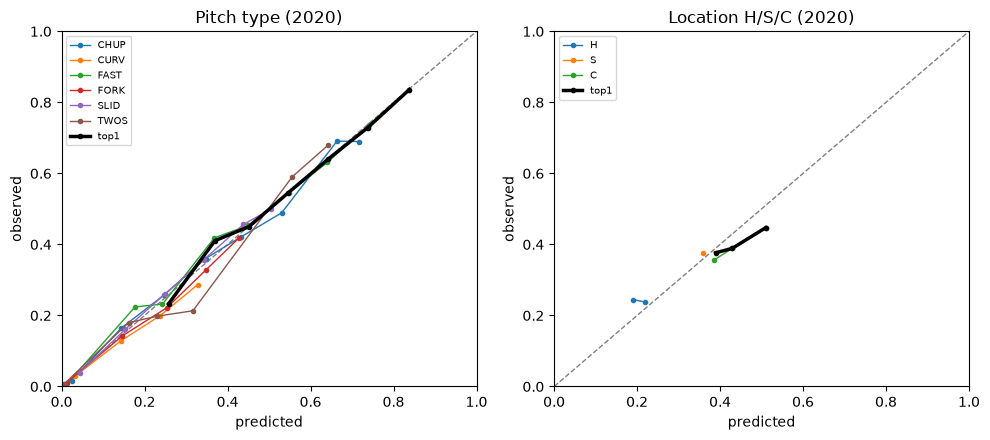

In [43]:
major = [c for c in CLASSES if (y_t == CLASSES.index(c)).mean() >= 0.03] + ["1등 예측"]  # 3% 이상 구종만 그림
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
calib_plot(tab_type, "Pitch type (2020)", axes[0], show=major)
calib_plot(tab_hsc, "Location H/S/C (2020)", axes[1])
plt.tight_layout()
plt.show()

구종

- 모든 구종이 대각선을 따라감 → 구종 확률은 숫자 그대로 믿고 써도 됨
- 투심이 예측 30% 근처에서 대각선 아래로 처짐 (공 수가 적은 구종이라 확실하지 않음)
- 확률이 0~84%까지 넓게 퍼져 있음 → 공마다 다른 확률을 줄 줄 앎, 구분력 있음

위치

- 점이 아주 좁은 범위에 몰려 있음
- H는 19-22%, S는 36% 근처, C는 38-42%에만 점이 찍힘
- 공마다 항상 비슷한 비율 예측 -> 구분력 거의 없음
- 보정이 맞더라도 확률이 한 점에 몰려 있으면 쓸모없음 -> 위치는 보정보다 구분력이 더 큰 문제


구종 확률이 잘 보정되어 있음 -> 위치 예측에서 구종 확률로 섞는 방식의 전제 성립

In [44]:
# Brier 점수 분해 (보정 / 구분력 / 원래 난이도)
# 항목별 Brier = 보정 오차 − 구분력 + 불확실성 (구간 기준 근사)
def brier_decomp(P, y, labels, bins=BINS):  
    rows = []
    for k, lab in enumerate(labels):
        p, o = P[:, k], (y == k).astype(float)
        b = np.clip(np.digitize(p, bins) - 1, 0, len(bins) - 2)
        g = pd.DataFrame({"b": b, "p": p, "o": o}).groupby("b").agg(n=("p", "size"), pm=("p", "mean"), om=("o", "mean"))
        N, obar = len(p), o.mean()
        rows.append({"항목": lab, "Brier": np.mean((p - o) ** 2),
                     "보정 오차": (g.n * (g.pm - g.om) ** 2).sum() / N,  # 작을수록 good
                     "구분력": (g.n * (g.om - obar) ** 2).sum() / N,  # 클수록 good
                     "불확실성": obar * (1 - obar)})
    t = pd.DataFrame(rows).set_index("항목")
    t.loc["합계"] = t.sum()
    return t

print("① 구종"); display(brier_decomp(P_t, y_t, CLASSES).round(4))
print("② 위치 H/S/C (실전)"); display(brier_decomp(P_g, y_g, ["H", "S", "C"]).round(4))

① 구종


,Brier,보정 오차,구분력,불확실성
항목,,,,
CHUP,0.0922,0.0002,0.0237,0.1160
CURV,0.0645,0.0002,0.0049,0.0697
CUTT,0.0102,0.0001,0.0047,0.0148
FAST,0.2225,0.0003,0.0273,0.2496
FORK,0.0338,0.0001,0.0061,0.0404
KNUC,0.0013,0.0000,0.0000,0.0013
SINK,0.0000,0.0000,0.0000,0.0000
SLID,0.1400,0.0001,0.0153,0.1557
TWOS,0.0336,0.0003,0.0228,0.0563


② 위치 H/S/C (실전)


,Brier,보정 오차,구분력,불확실성
항목,,,,
H,0.1819,0.0006,0.0000,0.1816
S,0.2350,0.0003,0.0000,0.2347
C,0.2383,0.0016,0.0002,0.2369
합계,0.6552,0.0025,0.0002,0.6531


- 구종과 위치 모두 보정 오차 거의 0 -> 확률 숫자 자체는 믿을 만함
- 구분력이 차이 만듦: 구종은 원래 난이도 15%를 줄임 (구분력 0.105 / 불확실성 0.704), 위치는 0.0002로 사실상 0 -> 위치 구분력 거의 없음
- 위치 Brier 0.655 ≈ 불확실성 0.653 -> 항상 같은 비율을 말하는 것과 거의 같은 점수
- 구종별로는 직구(0.027)·체인지업(0.024)·투심(0.023)에서 구분력이 큼, 커브·포크·커터는 작음

In [45]:
# 재보정 전후 log loss
def fit_recal(P, y, iters=50):  # log loss가 (a, b)에 대해 볼록 -> Newton법으로 몇 번 만에 최솟값
    L = np.log(np.clip(P, 1e-12, None))
    n, K = P.shape
    Y = np.eye(K)[y]  # 정답 원-핫
    G = np.concatenate([L[:, :, None], np.broadcast_to(np.eye(K), (n, K, K))], 2)  # (n, K, 1+K): 로짓 z_k를 (a, b)로 미분
    loss = lambda th: -log_softmax(th[0] * L + th[1:], axis=1)[np.arange(n), y].mean()  # 재보정: 새 확률 = softmax(a × log P + b), a = 1/온도 (<1이면 확률을 덜 확신), b = 항목별 보정값
    th = np.r_[1.0, np.zeros(K)]  # a=1, b=0: 원래 확률에서 출발
    for _ in range(iters):
        S = np.exp(log_softmax(th[0] * L + th[1:], axis=1))  # 지금 (a, b)로 만든 확률
        grad = np.einsum("nk,nkp->p", S - Y, G) / n  # 기울기
        W = S[:, :, None] * np.eye(K) - S[:, :, None] * S[:, None, :]  # softmax 미분 (n, K, K)
        H = np.einsum("nkp,nkl,nlq->pq", G, W, G) / n + 1e-6 * np.eye(K + 1)  # 2차 미분 (b는 다같이 더해도 결과 같아서 아주 작은 값 더하여 안정화)
        step, f0 = np.linalg.solve(H, grad), loss(th)
        t = 1.0
        while loss(th - t * step) > f0 and t > 1e-4:  # 오히려 나빠지면 보폭 절반
            t /= 2
        th = th - t * step
        if np.abs(t * step).max() < 1e-8:
            break
    return lambda Pn: np.exp(log_softmax(th[0] * np.log(np.clip(Pn, 1e-12, None)) + th[1:], axis=1))

def recal_report(Pv, yv, Pt_, yt_, labels):  # 2019로 맞추고 2020에 적용
    f = fit_recal(Pv, yv)
    ll = lambda P, y: -np.log(np.clip(P[np.arange(len(y)), y], 1e-12, None)).mean()
    raw, rec = ll(Pt_, yt_), ll(f(Pt_), yt_)
    return {"log loss (원래)": raw, "log loss (재보정 후) = 구분력 몫": rec, "보정으로 줄일 수 있던 몫": raw - rec}

q19 = pp[pp["GYEAR"].eq(VAL_YEAR)]
P_t19 = q19[["p_type_" + c for c in CLASSES]].to_numpy()
y_t19 = q19["pitch_type"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
P_g19 = q19[["p_zone_" + z for z in ZONES]].to_numpy() @ GROUP2
y_g19 = q19["zone"].str[0].map({"H": 0, "S": 1, "C": 2}).to_numpy()

display(pd.DataFrame({"① 구종": recal_report(P_t19, y_t19, P_t, y_t, CLASSES),
                      "② 위치 H/S/C (실전)": recal_report(P_g19, y_g19, P_g, y_g, ["H", "S", "C"])}).T.round(4))

,log loss (원래),log loss (재보정 후) = 구분력 몫,보정으로 줄일 수 있던 몫
① 구종,1.1018,1.1072,-0.0054
② 위치 H/S/C (실전),1.0800,1.0773,0.0027


- 구종은 이미 보정이 잘 되어 있어 2019년에 맞춘 재보정을 2020에 적용하면 오히려 조금 나빠짐
- 위치는 Chase 과대평가를 조금 잡아 0.003 줄어들지만 남는 1.077이 대부분 -> 구분력 부족

## 10. 분류 지표

1등으로 고른 것 하나만 보고 채점 (확률 무시)


In [46]:
def class_report(y, yhat, labels):  # y, yhat: 정답·예측 번호
    K = len(labels)
    cm = np.zeros((K, K), int)  # K×K 크기의 0으로 채운 표
    np.add.at(cm, (y, yhat), 1)  # 공마다 cm[실제, 예측] 칸에 1씩 더하기
    tp, true_n, pred_n = np.diag(cm), cm.sum(1), cm.sum(0)  # tp: 대각선(구종별 맞힌 개수), true_n: 행 합(구종별 실제 개수), pred_n: 열 합(구종별 예측한 개수)
    with np.errstate(invalid="ignore", divide="ignore"):  # 한 번도 예측 안 한 구종은 precision 없음 (NaN)
        rep = pd.DataFrame({"실제 개수": true_n, "예측 개수": pred_n, "precision": tp / pred_n,
                            "recall": tp / true_n, "F1": 2 * tp / (true_n + pred_n)}, index=labels)
    rep = rep[rep["실제 개수"] > 0]  # 2020에 없는 구종 제외 (SINK 등)
    rep["F1"] = rep["F1"].fillna(0)
    total = {"accuracy": tp.sum() / len(y), "balanced accuracy": rep["recall"].mean(), "macro F1": rep["F1"].mean()}  # 전체 지표
    cmn = pd.DataFrame(cm / np.maximum(true_n[:, None], 1), index=labels, columns=labels).loc[rep.index, rep.index]  # 비율 혼동행렬
    return rep, total, cmn

In [47]:
# 2020 실전
rep_t, tot_t, cm_t = class_report(y_t, P_t.argmax(1), CLASSES)
rep_g, tot_g, cm_g = class_report(y_g, P_g.argmax(1), ["H", "S", "C"])

# 비교 기준
tot_t0 = class_report(y_t, np.full_like(y_t, CLASSES.index("FAST")), CLASSES)[1]
tot_g0 = class_report(y_g, np.full_like(y_g, 2), ["H", "S", "C"])[1]

In [48]:
display(pd.DataFrame({"① 구종: 항상 FAST": tot_t0, "① 구종 (B4)": tot_t,
                      "② H/S/C: 항상 C": tot_g0, "② 위치 H/S/C (실전)": tot_g}).T.round(4))

,accuracy,balanced accuracy,macro F1
① 구종: 항상 FAST,0.4793,0.1250,0.0810
① 구종 (B4),0.5244,0.2576,0.2576
② H/S/C: 항상 C,0.3853,0.3333,0.1854
② 위치 H/S/C (실전),0.3883,0.3362,0.2113


- 구종: accuracy 차이는 작지만, 구종마다 같은 무게를 주는 balanced accuracy·macro F1은 2-3배 -> 투수별 기록 덕분에 직구 외 구종도 일부 맞힘
- 위치: 세 지표 모두 "무조건 Chase"와 거의 같음 -> 1등 예측 기준으로는 투수 정보 쓴 효과 거의 없음

In [49]:
print("① 구종 - 구종별"); display(rep_t.round(3))

① 구종 - 구종별


,실제 개수,예측 개수,precision,recall,F1
CHUP,1689,763,0.457,0.207,0.285
CURV,951,123,0.146,0.019,0.034
CUTT,189,92,0.402,0.196,0.263
FAST,6047,10231,0.536,0.907,0.674
FORK,532,22,0.409,0.017,0.032
KNUC,17,0,NaN,0.000,0.000
SLID,2434,614,0.415,0.105,0.167
TWOS,756,770,0.600,0.611,0.606


- 직구 과다 예측-> recall 0.91로 직구는 거의 다 잡지만 precision은 0.54
- 직구 다음으로 투심이 잘 맞음 (precision 0.60으로 가장 높음) -> 초구로 투심을 주무기처럼 쓰는 투수들은 습관이 뚜렷해서 기록만으로도 잘 맞음
- 체인지업, 커터: 고르면 절반 가까이 맞지만 실제 공의 80%는 놓침
- 슬라이더: 두 번째로 많은 구종이지만 예측 적음
- 커브, 포크: 거의 예측하지 않음
- 너클: 예측하지 않음

In [50]:
print("① 구종 - 혼동행렬 (행 = 실제)"); display(cm_t.round(2))

① 구종 - 혼동행렬 (행 = 실제)


,CHUP,CURV,CUTT,FAST,FORK,KNUC,SLID,TWOS
CHUP,0.21,0.01,0.00,0.70,0.00,0.0,0.01,0.07
CURV,0.07,0.02,0.01,0.78,0.00,0.0,0.09,0.05
CUTT,0.00,0.00,0.20,0.80,0.00,0.0,0.00,0.00
FAST,0.04,0.00,0.01,0.91,0.00,0.0,0.03,0.00
FORK,0.01,0.00,0.00,0.89,0.02,0.0,0.00,0.09
KNUC,0.41,0.29,0.00,0.00,0.00,0.0,0.24,0.06
SLID,0.02,0.01,0.00,0.83,0.00,0.0,0.10,0.03
TWOS,0.04,0.03,0.00,0.24,0.00,0.0,0.08,0.61


- 직구가 아닌 구종 대부분이 직구로 (실제 체인지업 70%, 커브 78%, 커터 80%, 슬라이더 83%, 포크 89%)
- 투심만 예외: 실제 투심 24% 직구로 -> 같은 패스트볼 계열끼리 헷갈림
- 너클(공 수 너무 적음)은 체인지업, 커브, 슬라이더로 나뉨

대부분 투수가 초구로 직구를 가장 많이 던져서 다른 구종에 30-40% 확률 줘도 1등 되지 못함 -> 다른 구종을 모르는 게 아니라 1등만 뽑는 방식의 한계

In [51]:
print("② 위치 H/S/C - 항목별"); display(rep_g.round(3))

② 위치 H/S/C - 항목별


,실제 개수,예측 개수,precision,recall,F1
H,3008,0,NaN,0.000,0.000
S,4746,526,0.407,0.045,0.081
C,4861,12089,0.387,0.964,0.553


- 거의 모든 공 Chase로 예측, Heart는 예측하지 않음
- Chase recall=0.964 -> 거의 모든 공을 C로 찍어서 높은 것, precision 0.387은 실제 C 비율(38.5%)과 같음 -> 실력 아님
- Shadow로 예측한 공 중 실제 Shadow 40.7% > 전체 Shadow 비율 37.6% → 아주 약한 신호는 있지만 공 수 적음

In [52]:
print("② 위치 H/S/C - 혼동행렬 (행 = 실제)"); display(cm_g.round(2))

② 위치 H/S/C - 혼동행렬 (행 = 실제)


,H,S,C
H,0.0,0.04,0.96
S,0.0,0.05,0.95
C,0.0,0.04,0.96


- 행끼리 차이 없음 -> 예측이 실제 위치에 대한 정보를 전혀 담지 못함
- H/S/C 확률이 좁게 몰려 있음 -> 그중 C가 항상 근소하게 1등
- 다만 1등 하나만 볼 때 얘기, 24칸 확률(log loss)로는 기준선보다 조금 나음 (2.9948 → 2.9403)

## 11. 실전 출력 - 누적 80%까지 구종 보여 주기

- 확률 높은 구종부터 누적 확률이 80%가 될 때까지 보여 줌 → 직구가 압도적인 투수는 1개, 고르게 섞는 투수는 여러 개
- 구종마다 위치(그 구종일 때 가능성 높은 칸 3개)를 같이 보여 주고, 나머지는 기타로 묶음
- 채점(log loss)은 그대로 9개 전체 사용, 보여 주는 방식만 확인


In [53]:
SHOW_P = 0.8

def show_types(P, thr=SHOW_P, k=None):  # 공마다 보여 줄 구종 (T/F), k를 주면 상위 k개 고정
    order = np.argsort(-P, 1)  # 확률 높은 순서
    if k is None:
        cum = np.take_along_axis(P, order, 1).cumsum(1)
        k = (cum < thr).sum(1) + 1  # 누적이 thr를 처음 넘는 구종까지 포함
    show = np.zeros(P.shape, bool)
    np.put_along_axis(show, order, np.arange(P.shape[1])[None, :] < np.reshape(k, (-1, 1)), 1)
    return show

# 2020 초구마다 구종별 24칸 확률 (보여 줄 구종 고를 때 사용)
q, Pt, yt = q_test, P_type_by["평가 2020"], y_type[test]
i = np.arange(len(q))
PZt = np.stack([loc_given_type(q, TEST_YEAR, t)[0] for t in CLASSES], 1)  # (n, 9구종, 24칸) 모든 공이 이 구종이라면 위치는?
show = show_types(Pt)  # 공마다 보여줄 구종(누적 80%) 선택
covered = show[i, yt]  # 실제 구종을 보여 줬나


In [54]:
# 비교 - 1개 / 2개 / 3개 고정 / 누적 80%
ways = {"1개 고정": show_types(Pt, k=1), "2개 고정": show_types(Pt, k=2),
        "3개 고정": show_types(Pt, k=3), f"누적 {SHOW_P:.0%}": show}
rows = {}
for w, s in ways.items():
    hit = s[i, yt]  # 보여준 구종 안에 실제 구종이 있나
    rows[w] = {"보여 준 구종 수 평균": s.sum(1).mean(), "실제 구종 포함률": hit.mean(),
               "보여 준 확률 합 평균": (Pt * s).sum(1).mean()}  # 보정이 잘 됐으면 포함률과 비슷
display(pd.DataFrame(rows).T.round(3))

,보여 준 구종 수 평균,실제 구종 포함률,보여 준 확률 합 평균
1개 고정,1.00,0.524,0.523
2개 고정,2.00,0.811,0.805
3개 고정,3.00,0.932,0.931
누적 80%,2.51,0.904,0.896


- 네 방식 모두 실제 포함률과 보여 준 확률 합이 1%p 이내로 일치 -> 구종 확률의 보정 good
- 2개 고정 → 누적 80%: 평균 0.51개 더 보여 주고 포함률 +9.3%p (81.1% → 90.4%)
- 3개 고정은 포함률 93.2%로 더 높지만 평균 0.49개 더 보여 줌 -> 누적 80%가 개수 대비 효율 좋음 (확실한 공은 적게, 애매한 공은 많이)

In [55]:
print("누적 80% - 보여 준 구종 수 분포")
display(pd.Series(show.sum(1)).value_counts(normalize=True).sort_index().round(3).to_frame("비율"))

누적 80% - 보여 준 구종 수 분포


,비율
1,0.014
2,0.525
3,0.400
4,0.058
5,0.003


- 1개만 보여준 공 1.4% -> 모델이 한 구종에 80% 넘게 확신하는 경우 거의 없음 -> 2 or 3개를 공마다 고르는 방식에 가까움
- 4개 이상은 구종을 고르게 섞는 일부 투수에서

In [57]:
# 투수별
display(pd.DataFrame({"pitcher": q["pitcher_code"].map(names), "n": 1, "보여 준 구종 수": show.sum(1), "포함률": covered})
        .groupby("pitcher").agg({"n": "sum", "보여 준 구종 수": "mean", "포함률": "mean"})
        .sort_values("보여 준 구종 수").round(2))

,n,보여 준 구종 수,포함률
pitcher,,,
고우석,131,1.34,0.88
김강률,118,1.67,0.89
조상우,180,1.72,0.94
김민수,481,2.00,0.95
김진성,165,2.00,0.87
이재학,393,2.00,0.96
양현종,749,2.00,0.95
김재윤,178,2.00,0.99
장현식,201,2.00,0.89


- 가장 적게: 고우석, 김강률, 조상우 -> 직구 위주 불펜투수
- 정확히 2개: 양현종, 이재학, 김재윤, 함덕주, 홍건희 등 9명 -> 초구를 사실상 두 구종으로 던지는 투수
- 가장 많이: 노경은, 박세웅, 우규민, 이용찬 -> 노경은 1등 예측 적중률 27% but 4개 보여주면 90%
- 포함률: 실제 구종이 보여 준 구종 안에 있었던 비율 -> 모든 투수 85% 이상 -> 특정 투수에서 모델이 크게 무너지는 경우 없음

In [58]:
def card(j):  # j: 2020 초구 중 j번째 공의 실전 출력
    r = q.iloc[j]
    print(f"{names.get(r['pitcher_code'], r['pitcher_code'])} vs {'같은' if r['same_side'] else '반대'} 손 타자 | {r['gameID']}")
    for t in np.argsort(-Pt[j]):
        if not show[j, t]:
            continue
        z3 = np.argsort(-PZt[j, t])[:3]  # 가능성 높은 칸 3개
        print(f"  {CLASSES[t]:5s}{Pt[j, t]:6.1%} | "
              + ", ".join(f"{ZONES[z]} {PZt[j, t, z]:.0%}" for z in z3))
    print(f"  기타 {1 - Pt[j, show[j]].sum():6.1%}")  # 보여주지 않은 구종들의 확률 합
    print(f"  → 실제: {r['pitch_type']}, {r['zone']}")  # 정답

In [59]:
pname = q["pitcher_code"].map(names).to_numpy()
for p in ["고우석", "양현종", "노경은"]:  # 직구 위주 / 중간 / 고르게 섞는 투수 예시
    card(np.flatnonzero(pname == p)[0])
    print()

고우석 vs 같은 손 타자 | 20200508LGNC0
  FAST  79.3% | C_밖 15%, C_높 10%, C_몸 7%
  SLID  17.5% | C_밖 16%, C_낮 14%, C_높 7%
  기타   3.2%
  → 실제: FAST, C_밖

양현종 vs 같은 손 타자 | 20200505WOHT0
  FAST  74.8% | C_높 13%, C_낮 8%, C_밖 8%
  SLID  18.7% | C_낮 15%, C_밖 12%, C_높 8%
  기타   6.5%
  → 실제: FAST, H_상밖

노경은 vs 반대 손 타자 | 20200508SKLT0
  CURV  30.0% | C_낮 14%, C_밖 10%, C_높 10%
  CHUP  20.5% | C_밖 18%, C_낮 15%, S_하-밖띠 6%
  TWOS  18.2% | C_밖 17%, C_낮 8%, H_하밖 7%
  FAST  13.5% | C_밖 13%, C_몸 9%, C_높 8%
  기타  17.8%
  → 실제: FAST, H_상몸

